# 09a – Combining NIRCam + MIRI (NGC 6720): two approaches and a reference

**What:** Combine MIRI filters with the NIRCam images from notebook 08 into colour images – in two ways and, for an honest comparison, additionally in a scientifically clean reference version.

| Version | Filter → colour | Sharpness | Classification |
|---|---|---|---|
| **W1** – like Wesson et al. Fig. 3 | F300M blue, F560W green, F770W red | MIRI upsampled | chromatic, aesthetic |
| **W2** – ionisation layers | F1500W ([Ne III]) blue, F162M cyan, F212N (H₂) orange, F770W red; brightness partly from F335M (LRGB) | MIRI upsampled + sharp luminance | physically grouped, aesthetic |
| **W2s** – reference | as W2, without LRGB | **all filters brought to the sharpness of F1500W (≈ 0.49″)** | scientifically clean |

**Honest classification:** in W1 and W2, MIRI images are upsampled onto the finer NIRCam grid (0.063″). This creates *no* new detail; the MIRI parts remain blurred, only the NIRCam parts are sharp. Colour and sharpness thus come from data of different resolution – an **aesthetic** decision. The filters would only be properly comparable at equal resolution (W2s). Microscopy analogy: overlaying a confocal and a widefield image looks nice; for a colocalisation analysis both would have to be brought to the same PSF.

**Result:** MIRI (F560W, F770W, F1500W) brought onto the NIRCam grid and aligned to NIRCam by ≈ 78 mas (residual offset 0.17–0.26 px). Three versions compared; exported were **W2** (ionisation layers, brightness partly from F335M, aesthetic) and **W2s** (equal sharpness for all filters, reference), crop 1.40′ × 1.05′.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import warnings
from scipy.ndimage import gaussian_filter, distance_transform_edt
from astropy.io import fits
from astropy.wcs import WCS, FITSFixedWarning

from astropipe import bands, registration, stretch, color, export

warnings.simplefilter("ignore", FITSFixedWarning)
TARGET = "ngc6720"
ROOT = Path("..")
NIR_REPROJ = ROOT / "data" / f"{TARGET}_nircam_reproj_lw"
NIR_PREFIX = f"{TARGET}_lw_dsl"                       # destriped (local model), see notebook 08b
NIR_STRETCHED = ROOT / "data" / f"{TARGET}_nircam_stretched"
MIRI_RAW = ROOT / "data" / f"{TARGET}_miri"
MIRI_REPROJ = ROOT / "data" / f"{TARGET}_miri_reproj_lw"
P_NIR = json.loads((ROOT / "params" / f"{TARGET}_stretch.json").read_text())

NIR_BANDS = ["F162M", "F212N", "F300M", "F335M"]
MIRI_BANDS = ["F560W", "F770W", "F1500W"]

# target grid = the NIRCam grid from notebook 08 (0.063″/px, north up)
ref_hdr = fits.getheader(NIR_REPROJ / f"{NIR_PREFIX}_f335m_reproj.fits", 0)
wcs_out = WCS(ref_hdr)
shape_out = (ref_hdr["NAXIS2"], ref_hdr["NAXIS1"])
print("target grid:", shape_out, registration.pixel_scale_arcsec(wcs_out))

target grid: (3311, 3312) [0.063 0.063]


## 1. Bringing MIRI onto the NIRCam grid

`reproject_adaptive` as before – this time **upsampling** (0.111″ → 0.063″, factor ≈ 1.76). The images become larger, but not sharper.

In [2]:
MIRI_I2D = {bands.band_from_header(fits.getheader(f, 0)): f for f in sorted(MIRI_RAW.glob("*_i2d.fits"))}
MIRI_FILES = registration.reproject_all({b: MIRI_I2D[b] for b in MIRI_BANDS}, wcs_out, shape_out,
                                        MIRI_REPROJ, f"{TARGET}_miri_on_lw")

F560W   exists -> ngc6720_miri_on_lw_f560w_reproj.fits
F770W   exists -> ngc6720_miri_on_lw_f770w_reproj.fits
F1500W  exists -> ngc6720_miri_on_lw_f1500w_reproj.fits


## 2. Do MIRI and NIRCam match? (star check)

Same method as in stage 3, reference F335M. In MIRI, stars are wider and fainter at long wavelengths – the centroids become less precise; an offset of a few tenths of a pixel (on the 0.063″ grid) would be unremarkable.

In [3]:
lin = {}
for b in NIR_BANDS:
    lin[b] = fits.getdata(NIR_REPROJ / f"{NIR_PREFIX}_{b.lower()}_reproj.fits").astype(np.float32)
for b in MIRI_BANDS:
    lin[b] = fits.getdata(MIRI_FILES[b]).astype(np.float32)

check = {b: lin[b] for b in ["F335M"] + MIRI_BANDS}
off = registration.star_offsets(check, "F335M", half=7)
for b in MIRI_BANDS:
    o = off[b]
    print(f"{b:<7} median offset vs F335M: {np.median(o):.2f} px = {np.median(o) * 63:.0f} mas ({len(o)} stars)" if o
          else f"{b:<7} no stars measured")

F560W   median offset vs F335M: 1.24 px = 78 mas (7 stars)
F770W   median offset vs F335M: 1.22 px = 77 mas (7 stars)
F1500W  median offset vs F335M: 2.56 px = 161 mas (7 stars)


In [4]:
shifts = registration.star_shifts(check, "F335M", half=7)
for b in MIRI_BANDS:
    s = shifts[b]
    print(f"{b:<7} dy {np.median(s[:, 0]):+.2f}  dx {np.median(s[:, 1]):+.2f} px   "
          f"scatter dy {np.std(s[:, 0]):.2f}  dx {np.std(s[:, 1]):.2f}  ({len(s)} stars)")

# all MIRI filters share one grid -> one common shift, measured on the sharpest filters
both = np.vstack([shifts["F560W"], shifts["F770W"]])
DY, DX = np.median(both[:, 0]), np.median(both[:, 1])
print(f"applied MIRI shift: dy {-DY:+.2f}, dx {-DX:+.2f} px")
for b in MIRI_BANDS:
    lin[b] = registration.apply_shift(lin[b], -DY, -DX)

off2 = registration.star_offsets({b: lin[b] for b in ["F335M"] + MIRI_BANDS}, "F335M", half=7)
for b in MIRI_BANDS:
    print(f"{b:<7} after shift: median offset {np.median(off2[b]):.2f} px")

F560W   dy -1.06  dx +0.67 px   scatter dy 0.12  dx 0.08  (7 stars)
F770W   dy -1.03  dx +0.65 px   scatter dy 0.55  dx 0.11  (7 stars)
F1500W  dy -1.15  dx +1.92 px   scatter dy 1.95  dx 1.16  (7 stars)
applied MIRI shift: dy +1.04, dx -0.67 px
F560W   after shift: median offset 0.17 px
F770W   after shift: median offset 0.26 px
F1500W  after shift: median offset 2.04 px


## 3. Common area and MIRI stretch

- Valid = data in **all seven** filters (overlap NIRCam ∩ MIRI); saturated cores are filled as before.
- NIRCam: the stretched images from notebook 08 are reused (same parameters).
- MIRI: sky boxes inside the overlap (rule score > 0), then the same asinh stretch.

In [5]:
filled = {}
for b in NIR_BANDS + MIRI_BANDS:
    lin[b], filled[b] = stretch.fill_saturated_holes(lin[b], max_hole_px=2000)
valid = stretch.common_valid({b: lin[b] for b in NIR_BANDS + MIRI_BANDS})
print("filled px:", filled)
print(f"valid in all 7 bands: {100 * valid.mean():.1f} % of the grid")

miri = {b: lin[b] for b in MIRI_BANDS}
BOX, EDGE, NBOX, MINSEP = 120, 80, 6, 350
boxes, scores = stretch.find_sky_boxes(miri, valid, BOX, EDGE, NBOX, MINSEP)
boxes_used = [bx for bx, s in zip(boxes, scores) if s > 0]
print(len(boxes_used), "of", len(boxes), "boxes used:", boxes_used, "scores:", np.round(scores, 4))
stats_miri = stretch.sky_stats(miri, boxes_used, BOX)
for b in MIRI_BANDS:
    s = stats_miri[b]
    print(f"{b:<7} bkg {s['bkg']:9.4f}  noise {s['noise']:8.4f}  spread/noise {s['spread'] / s['noise']:5.2f}")

filled px: {'F162M': 146, 'F212N': 51, 'F300M': 95, 'F335M': 85, 'F560W': 1642, 'F770W': 1642, 'F1500W': 2066}
valid in all 7 bands: 35.9 % of the grid
6 of 6 boxes used: [(1860, 540), (480, 1620), (2580, 1620), (1440, 2640), (2160, 780), (720, 1920)] scores: [0.4757 0.4758 0.4882 0.4922 0.4932 0.5023]
F560W   bkg    1.4488  noise   0.0818  spread/noise  2.35
F770W   bkg    4.2490  noise   0.1016  spread/noise  2.49
F1500W  bkg   38.4058  noise   0.1056  spread/noise  9.84


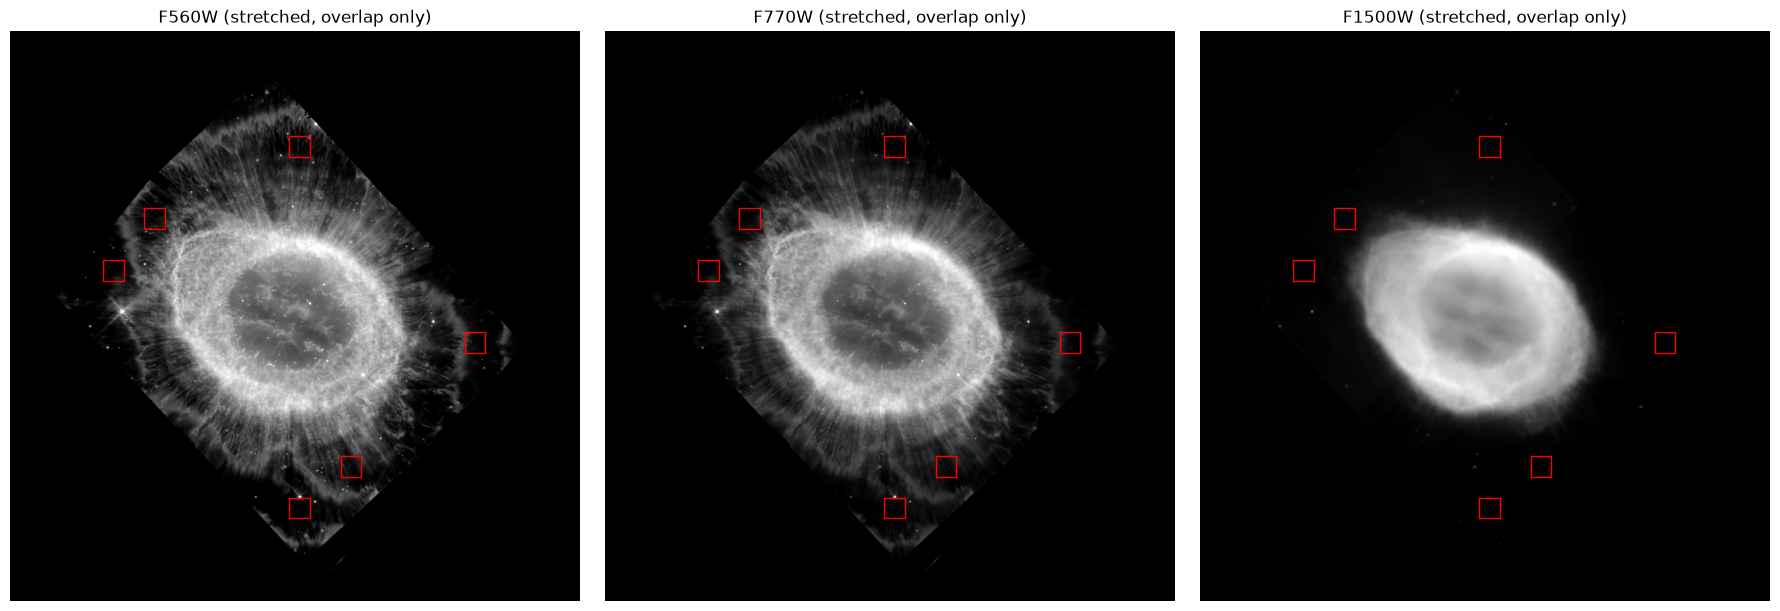

In [6]:
PARAMS_MIRI = {b: dict(black_k=0.5, white_pct=99.9, a=0.05) for b in MIRI_BANDS}
st_miri, lev_miri = stretch.stretch_all(miri, valid, stats_miri, PARAMS_MIRI)

st = {b: np.where(valid, fits.getdata(NIR_STRETCHED / f"{TARGET}_{b.lower()}_stretched.fits"), 0).astype(np.float32)
      for b in NIR_BANDS}
st.update(st_miri)

fig, axes = plt.subplots(1, len(MIRI_BANDS), figsize=(6 * len(MIRI_BANDS), 6))
for ax, b in zip(axes, MIRI_BANDS):
    ax.imshow(st[b], origin="lower", cmap="gray", vmin=0, vmax=1)
    for y, x in boxes_used:
        ax.add_patch(plt.Rectangle((x, y), BOX, BOX, fill=False, ec="red", lw=1))
    ax.set_title(f"{b} (stretched, overlap only)"); ax.axis("off")
plt.tight_layout()

## 4. Approach 1 and approach 2

Colours as hue angles (exactly reproducible). In W2, part of the brightness comes from F335M (`LUM_MIX`), so that the structure stays sharp while the colour also comes from the blurrier MIRI filters.

In [7]:
HUES = {
    "W1_wesson": {"F300M": 240, "F560W": 120, "F770W": 0},
    "W2_ionisation": {"F1500W": 230, "F162M": 190, "F212N": 25, "F770W": 0},
}
WEIGHTS = {"W1_wesson": {}, "W2_ionisation": {}}
LUM_BAND, LUM_MIX = "F335M", 0.5

rgb = {}
for name, h in HUES.items():
    rgb[name] = color.compose(st, color.mapping_from_degrees(h), WEIGHTS[name])
rgb["W2_ionisation"] = color.apply_luminance(rgb["W2_ionisation"], st[LUM_BAND], LUM_MIX)

## 5. Reference W2s: all filters at equal sharpness

Filters are only scientifically comparable at equal resolution. For this, the **linear** images (before stretching) are smoothed with a Gaussian kernel so that all have roughly the sharpness of F1500W: σ = √(FWHM_target² − FWHM_filter²) / 2.355.

FWHM values: MIRI from Wesson et al. 2024, Table 1. **NIRCam values are approximations from my knowledge of the JWST documentation – please check there if needed.** A Gaussian is also only an approximation of the real PSF (the diffraction spikes are not reproduced); it is good enough for the comparison.

Then the same stretch with the same black/white points as in W2 and the same colour assignment, without LRGB.

In [8]:
FWHM = {"F162M": 0.055, "F212N": 0.072, "F300M": 0.10, "F335M": 0.11,      # NIRCam: approx., check docs
        "F560W": 0.207, "F770W": 0.269, "F1500W": 0.488}                       # MIRI: Wesson et al. 2024
TARGET_FWHM = FWHM["F1500W"]
PIX = 0.063

def smooth_to(img, fwhm_in, fwhm_out):
    sig = np.sqrt(max(fwhm_out**2 - fwhm_in**2, 0)) / 2.3548 / PIX
    m = np.isfinite(img)
    num = gaussian_filter(np.where(m, img, 0), sig)
    den = gaussian_filter(m.astype(np.float32), sig)
    with np.errstate(invalid="ignore", divide="ignore"):
        out = num / den
    return np.where(m, out, np.nan).astype(np.float32), sig

def stretch_with_levels(img, bkg, black, white, a):
    y = np.clip((img - bkg - black) / (white - black), 0, 1)
    return np.where(valid, stretch.asinh_stretch(y, a), 0).astype(np.float32)

st_s = {}
for b in HUES["W2_ionisation"]:
    sm, sig = smooth_to(lin[b], FWHM[b], TARGET_FWHM)
    p = P_NIR["per_band"][b] if b in NIR_BANDS else {**stats_miri[b], **lev_miri[b], **PARAMS_MIRI[b]}
    st_s[b] = stretch_with_levels(sm, p["bkg"], p["black"], p["white"], p["a"])
    print(f"{b:<7} FWHM {FWHM[b]:.3f}″ -> {TARGET_FWHM:.3f}″ (sigma {sig:.1f} px)")
rgb["W2s_psf_matched"] = color.compose(st_s, color.mapping_from_degrees(HUES["W2_ionisation"]), WEIGHTS["W2_ionisation"])

F1500W  FWHM 0.488″ -> 0.488″ (sigma 0.0 px)
F162M   FWHM 0.055″ -> 0.488″ (sigma 3.3 px)
F212N   FWHM 0.072″ -> 0.488″ (sigma 3.3 px)
F770W   FWHM 0.269″ -> 0.488″ (sigma 2.7 px)


## 6. Comparison

Full image and a cutout at the ring. Things to look at:
- W1 vs. W2: what does each colour choice emphasise (halo arcs vs. layering)?
- W2 vs. W2s: how much sharpness does the aesthetic shortcut "give" us – and how much of it actually comes from a single filter (F335M/NIRCam)?

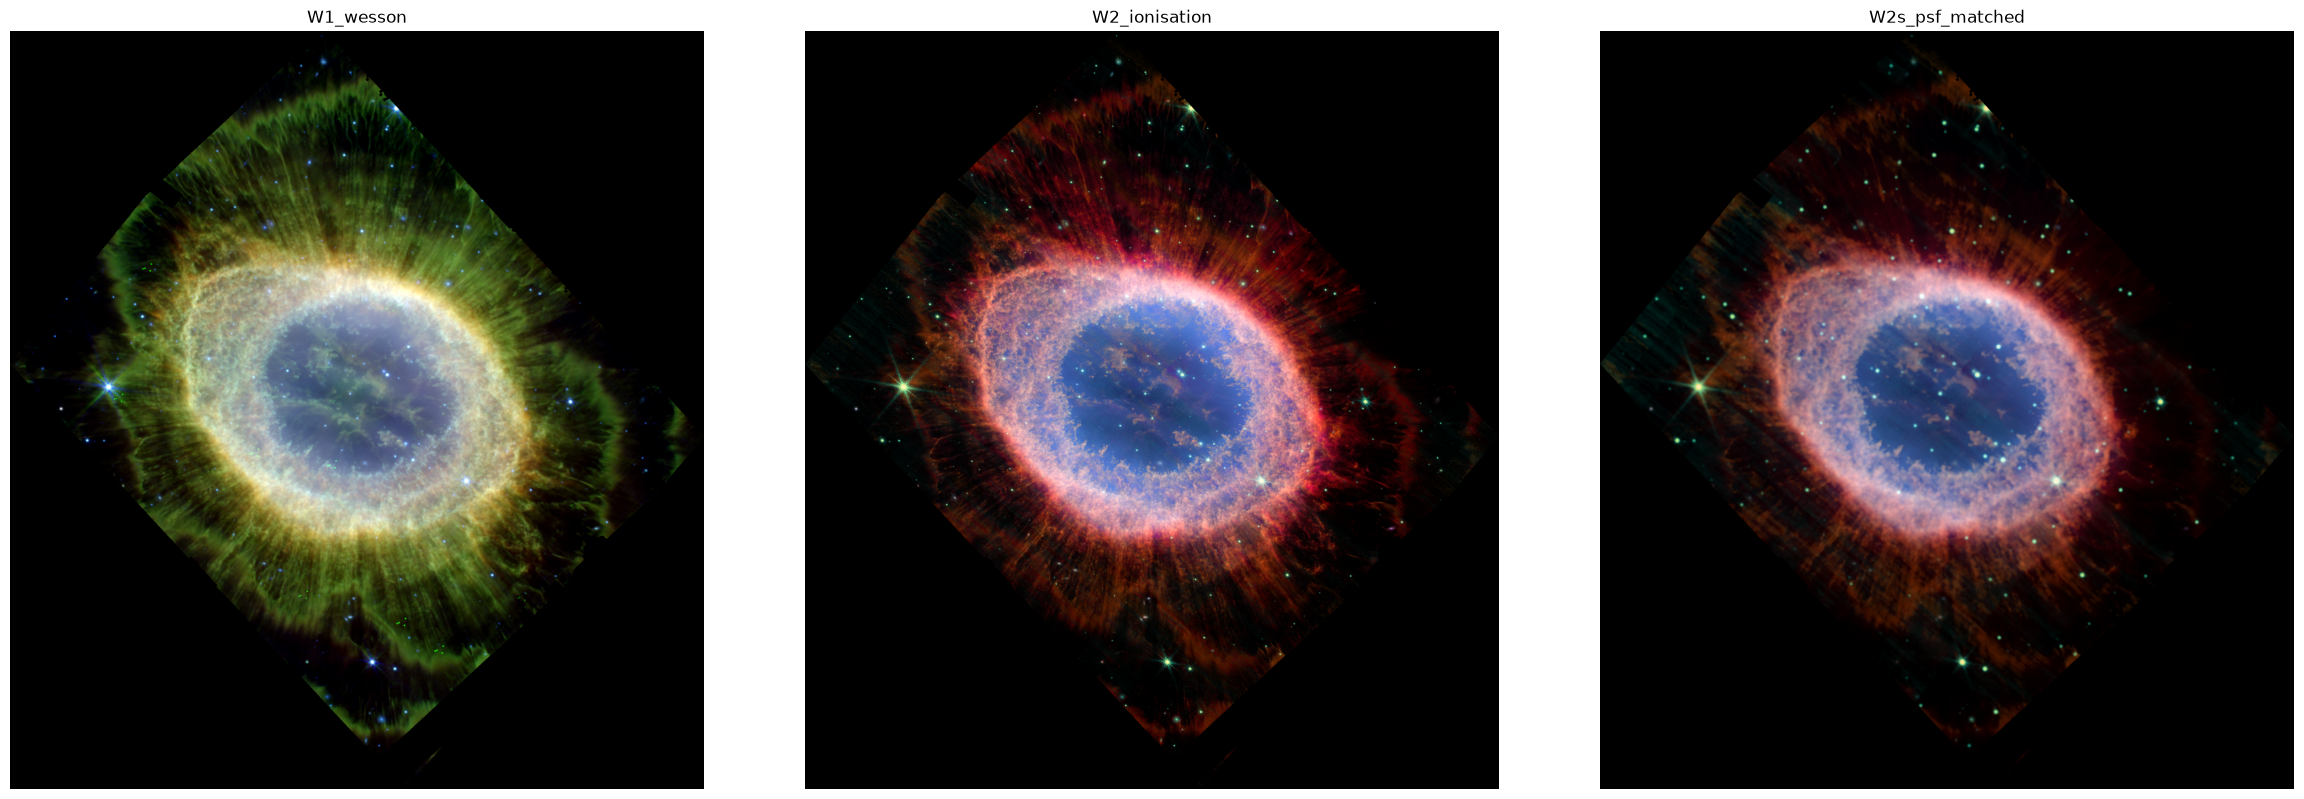

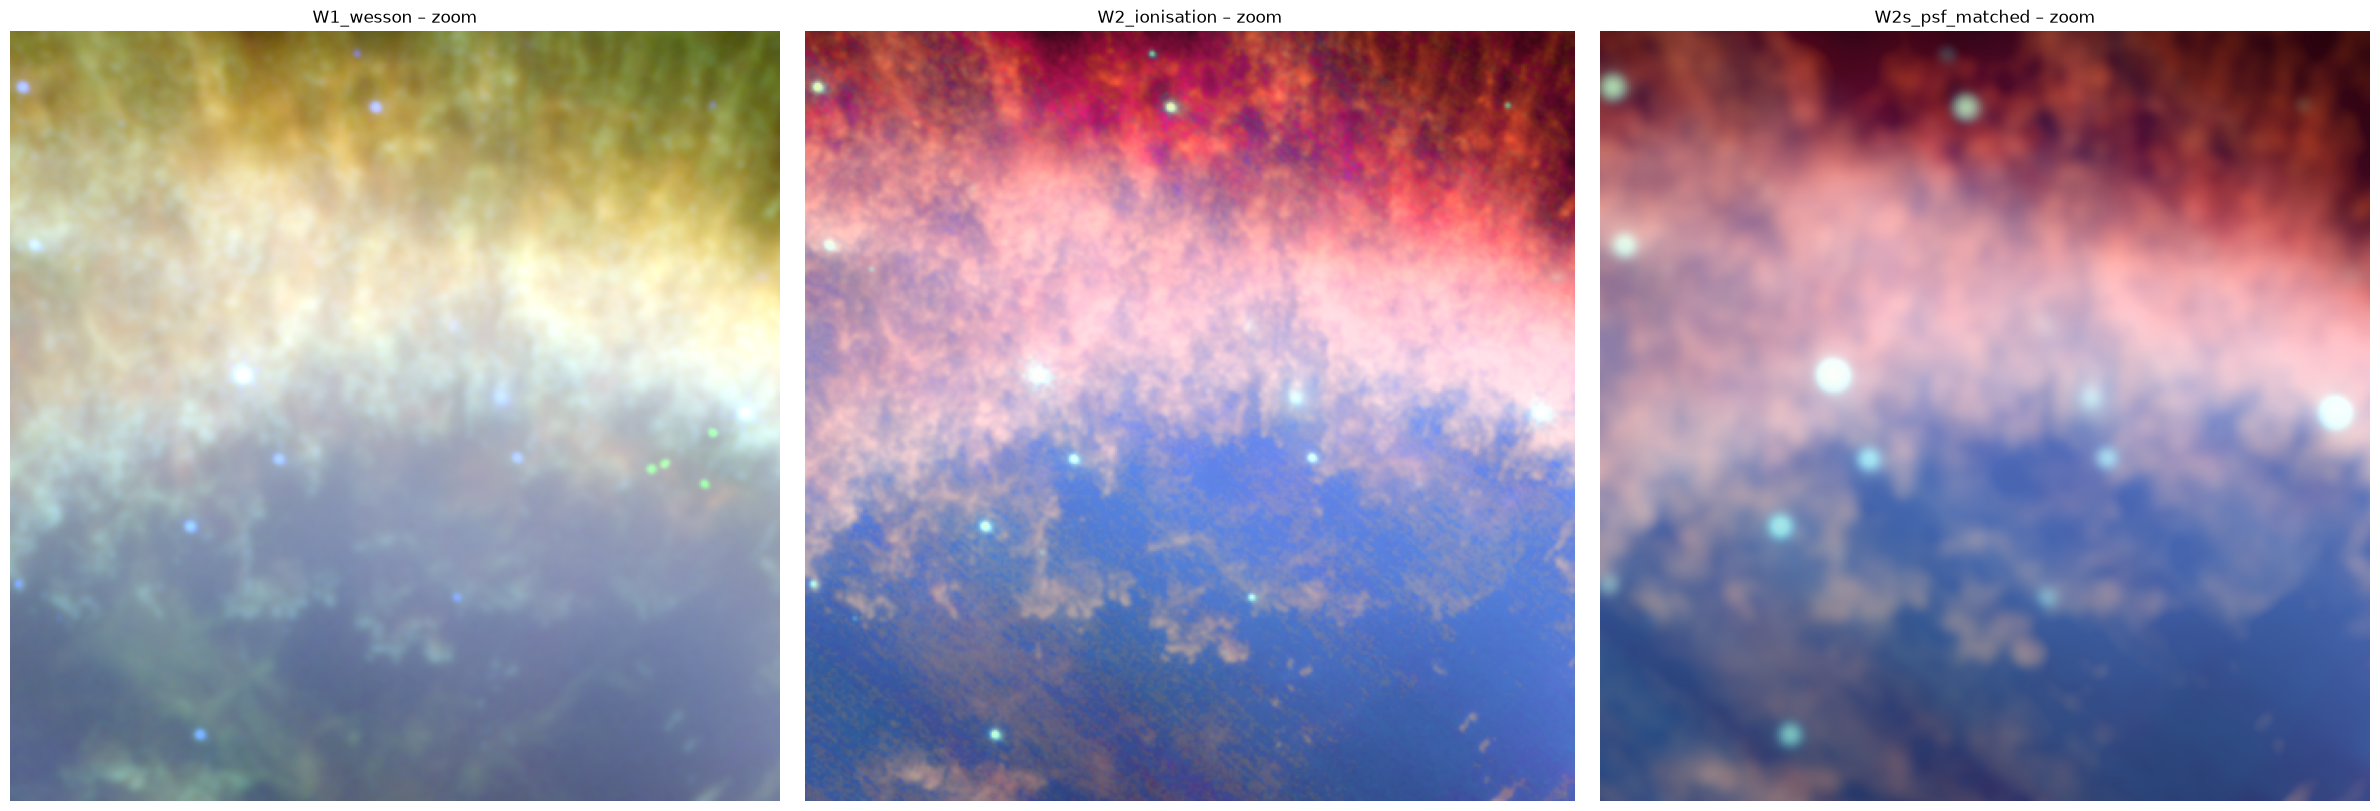

In [9]:
def bbox(mask):
    ys, xs = np.where(mask)
    return np.s_[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

full = bbox(valid)
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
for ax, name in zip(axes, rgb):
    ax.imshow(rgb[name][full], origin="lower"); ax.set_title(name); ax.axis("off")
plt.tight_layout()

cy, cx = export.nebula_center(st["F335M"], valid)
zoom_ = np.s_[cy + 150:cy + 550, cx - 200:cx + 200]     # adjust: part of the ring
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
for ax, name in zip(axes, rgb):
    ax.imshow(rgb[name][zoom_], origin="lower"); ax.set_title(f"{name} – zoom"); ax.axis("off")
plt.tight_layout()

## 7. Saving the parameters

In [10]:
rec = {
    "nircam": {"reproj": str(NIR_REPROJ), "prefix": NIR_PREFIX, "stretched": str(NIR_STRETCHED),
               "stretch_params": f"params/{TARGET}_stretch.json"},
    "miri": {"files": {b: MIRI_I2D[b].name for b in MIRI_BANDS}, "reproj": str(MIRI_REPROJ),
             "note": "upsampled 0.111 -> 0.063 arcsec/px with reproject_adaptive (no new detail)",
             "saturated_holes_filled_px": {b: filled[b] for b in MIRI_BANDS},
             "sky_boxes": {"size_px": BOX, "edge_margin_px": EDGE, "min_sep_px": MINSEP,
                           "rule": "score > 0", "yx": [list(map(int, b)) for b in boxes_used]},
             "per_band": {b: {**PARAMS_MIRI[b], **stats_miri[b], **lev_miri[b]} for b in MIRI_BANDS},
             "shift_px_applied": {"dy": float(-DY), "dx": float(-DX), "measured_on": ["F560W", "F770W"],
                                  "method": "registration.star_shifts vs F335M, median; registration.apply_shift"}},
    "variants": {name: {"hue_deg": HUES[name], "weights": WEIGHTS[name]} for name in HUES},
    "W2_luminance": {"band": LUM_BAND, "mix": LUM_MIX, "method": "astropipe.color.apply_luminance (Rec.709)"},
    "W2s_psf_matched": {"target_fwhm_arcsec": TARGET_FWHM, "fwhm_arcsec": FWHM,
                        "note": "Gaussian on linear images; NIRCam FWHM approximate", "luminance": None},
}
(ROOT / "params" / f"{TARGET}_nircam_miri.json").write_text(json.dumps(rec, indent=2))
print("saved params/%s_nircam_miri.json" % TARGET)

saved params/ngc6720_nircam_miri.json


## 8. Export (chosen version)

Only after the comparison. Crop again in 4:3 landscape inside the overlap (smaller edge margin than for NIRCam alone, because the overlap is smaller).

crop 1338 x 1004 px = 1.40′ x 1.05′, north up, east left
# Ring Nebula (NGC 6720, M57) – JWST NIRCam + MIRI (W2_ionisation)

Planetary nebula in the constellation Lyra, observed with NIRCam and MIRI on the James Webb Space Telescope (Cycle 1 GO programme 1558, PI M. Barlow). Field of view ≈ 1.4 × 1.1 arcmin, north up, east left.

**Aesthetic version.** 50 % of the brightness is taken from NIRCam F335M (LRGB technique) to keep fine structure sharp. Colour and sharpness therefore come from data of different resolution: the fine detail is from NIRCam, while the MIRI colours are intrinsically blurrier (FWHM up to ≈0.49″ for F1500W). A resolution-matched reference version (W2s) shows the same colour distribution without this shortcut.

## Colour assignment (chosen freely, grouped by ionisation state, not by wavelength)

| Filter | Colour | Mainly traces |
|---|---|---|
| F1500W | blue | MIRI – [Ne III] (≈94 %), highly ionised gas |
| F162M | light blue | NIRCam – continuum, presumably free-

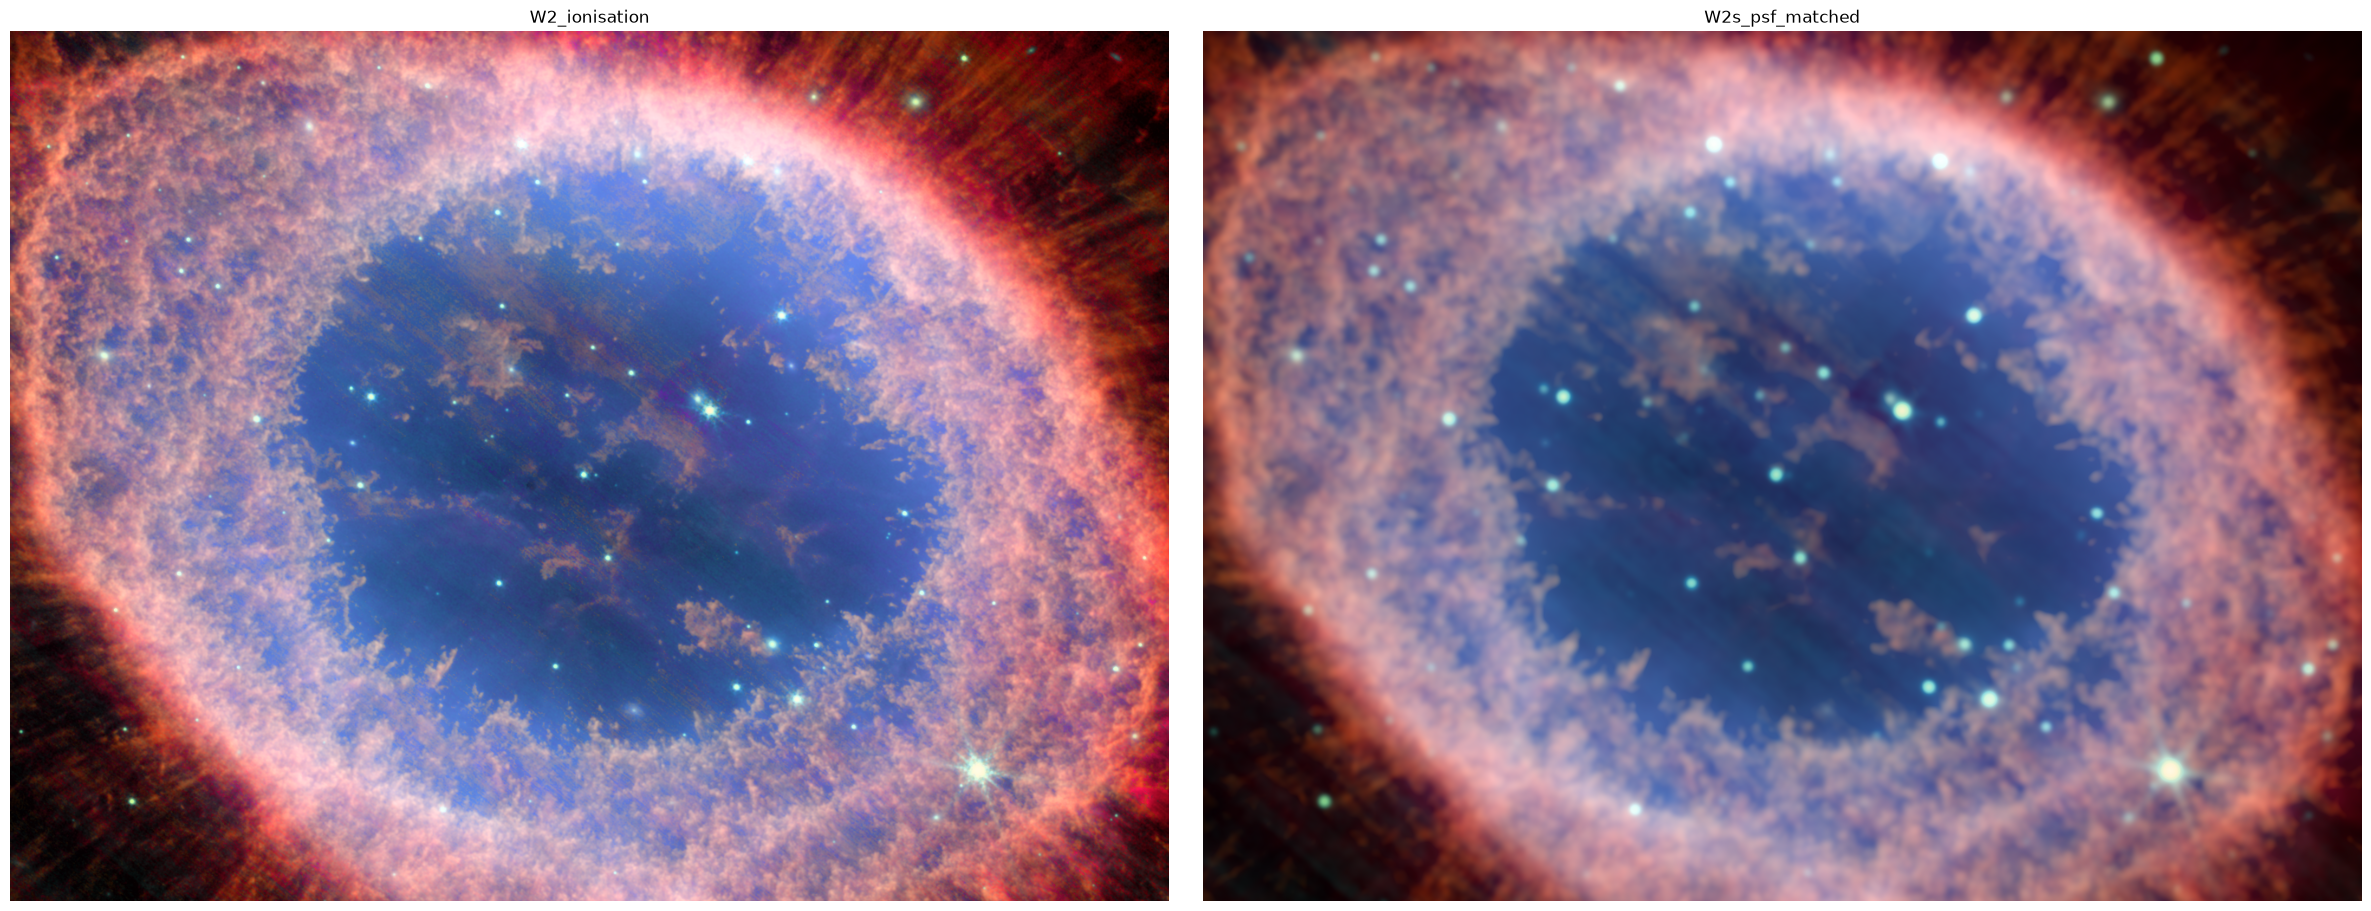

In [11]:
EXPORT = True          # set True when the preview looks right
EXPORT_VARIANTS = ["W2_ionisation", "W2s_psf_matched"]
MARGIN, ASPECT = 60, 4 / 3
AUTHOR = "Tritium13"

inner = distance_transform_edt(valid) > MARGIN
center = export.nebula_center(st["F335M"], valid)
half_h, half_w = export.largest_rect(inner, center, aspect=ASPECT)
cy, cx = center
crop = np.s_[cy - half_h:cy + half_h, cx - half_w:cx + half_w]
north_up, east_left = export.orientation(wcs_out, cy, cx)
size_w, size_h = 2 * half_w * PIX / 60, 2 * half_h * PIX / 60
orient = "north up, east left" if (north_up and east_left) else "ORIENTATION TO BE CHECKED"
print(f"crop {2 * half_w} x {2 * half_h} px = {size_w:.2f}′ x {size_h:.2f}′, {orient}")

COLOR_NAMES = {"F1500W": "blue", "F162M": "light blue", "F212N": "orange", "F770W": "red"}
CONTENT = {"F1500W": "MIRI – [Ne III] (≈94 %), highly ionised gas",
           "F162M": "NIRCam – continuum, presumably free-free emission from ionised gas, plus hydrogen recombination lines",
           "F212N": "NIRCam – molecular hydrogen (H2, ≈85 %)",
           "F770W": "MIRI – continuum, H2, [Ar II], PAH; concentric arcs most visible here"}
rows = "\n".join(f"| {b} | {COLOR_NAMES[b]} | {CONTENT[b]} |" for b in HUES["W2_ionisation"])

common_processing = (
    "NIRCam: calibrated stage-3 images (`_i2d.fits`), row destriping with a local background model, "
    "common grid 0.063″/px (`reproject_adaptive`). "
    f"MIRI: stage-3 mosaic (observation o001), reprojected onto the same grid, i.e. **upsampled from 0.111″/px** "
    f"(this creates no new detail), then shifted by dy = {-DY:+.2f}, dx = {-DX:+.2f} px "
    f"(≈ {np.hypot(DY, DX) * 63:.0f} mas) to match NIRCam star positions (measured on F560W/F770W). "
    "Background from sky boxes (relative: the halo fills most of the field), asinh stretch per filter "
    "(each normalised to its own white point), additive colour mixing. Saturated star cores filled with white. "
    "No local adjustments. Parameters: `params/ngc6720_stretch.json`, `params/ngc6720_nircam_miri.json`. Code: `src/astropipe`."
)

notes = {
    "W2_ionisation": (
        f"**Aesthetic version.** {int(LUM_MIX * 100)} % of the brightness is taken from NIRCam F335M (LRGB technique) to keep "
        "fine structure sharp. Colour and sharpness therefore come from data of different resolution: the fine detail is "
        "from NIRCam, while the MIRI colours are intrinsically blurrier (FWHM up to ≈0.49″ for F1500W). "
        "A resolution-matched reference version (W2s) shows the same colour distribution without this shortcut."
    ),
    "W2s_psf_matched": (
        f"**Resolution-matched reference.** Before stretching, all filters were smoothed with a Gaussian to the "
        f"resolution of F1500W (FWHM ≈ {TARGET_FWHM:.2f}″); no luminance layer. The filters are thus compared at equal "
        "resolution. NIRCam FWHM values used for the smoothing are approximate; a Gaussian only approximates the real PSF."
    ),
}

def caption_for(variant):
    return f"""# Ring Nebula (NGC 6720, M57) – JWST NIRCam + MIRI ({variant})

Planetary nebula in the constellation Lyra, observed with NIRCam and MIRI on the James Webb Space Telescope (Cycle 1 GO programme 1558, PI M. Barlow). Field of view ≈ {size_w:.1f} × {size_h:.1f} arcmin, {orient}.

{notes[variant]}

## Colour assignment (chosen freely, grouped by ionisation state, not by wavelength)

| Filter | Colour | Mainly traces |
|---|---|---|
{rows}

Filter contents follow the estimates in Wesson et al. 2024 (MNRAS; arXiv:2308.09027, Table 1), which refer to part of the bright ring. Blue → red runs roughly from highly ionised gas near the hot central star to molecular gas further out. The recorded light is infrared; all colours are an assignment, not "true" colours.

## Processing

{common_processing}

## Credits

Data: NASA, ESA, CSA, STScI (programme 1558, PI M. Barlow), retrieved via MAST. Processing: {AUTHOR}.
"""

fig, axes = plt.subplots(1, len(EXPORT_VARIANTS), figsize=(12 * len(EXPORT_VARIANTS), 9))
for ax, v in zip(np.atleast_1d(axes), EXPORT_VARIANTS):
    ax.imshow(rgb[v][crop], origin="lower"); ax.set_title(v); ax.axis("off")
plt.tight_layout()
print(caption_for("W2_ionisation"))

if EXPORT:
    for v in EXPORT_VARIANTS:
        for p in export.save_outputs(rgb[v][crop], caption_for(v), f"{TARGET}_nircam_miri_{v}",
                                     ROOT / "output" / "full_res", ROOT / "output"):
            print(f"{p.stat().st_size / 1e6:7.2f} MB  {p}")

## Conclusion

- **Upsampling:** MIRI was brought onto the NIRCam grid (0.111″ → 0.063″). This creates no new detail – openly documented as an aesthetic decision.
- **Offset between the instruments:** MIRI was offset by ≈ 1.25 px (≈ 78 mas) from NIRCam; F560W and F770W in the same direction (dy −1.05, dx +0.66 px), so a real offset. Corrected with a common shift → 0.17 and 0.26 px. F1500W measurement too uncertain (few, wide stars); same shift, since common grid.
- **Overlap:** valid in all 7 filters on 35.9 % of the grid, ring fully contained. MIRI background high and strongly uneven in F1500W.
- **W1 (like Wesson et al. Fig. 3):** halo arcs and rays strongly green (F560W), interior lavender. Green dots next to some stars are not an offset (they remained after the correction), but probably objects that are brighter at 5.6 µm than at 3 µm.
- **W2 (ionisation layers + LRGB from F335M):** clear layering from highly ionised (blue, inside) across the ring to molecular gas (red-orange, outside); sharp thanks to F335M as luminance.
- **W2s (equal sharpness):** practically the same colour distribution as W2 → the colours hold up at honest resolution too; the sharpness in W2 comes almost entirely from NIRCam.
- **Decision:** W2 as the main image, W2s as a reference next to it; both exported. W1 documented in the notebook.
- **Limits:** NIRCam sharpness values for W2s are approximations; Gaussian smoothing reproduces the real PSF only roughly; residual stripes from F162M still slightly visible in the interior.